# Question 3 — Stereo Vision Under Investigation: When Is Depth Trustworthy?
**Computer Vision Lab · Assignment 4**

**Data.** Two hand-held photos of a green plastic chair standing in front of a plain wall and a wooden cabinet (`chair_1.jpg`, `chair_2.jpg`, 1200×1600). The scene is a good stress-test: it contains **textureless surfaces** (wall, chair body), **reflective chrome legs**, **occlusions** (the wall behind/next to the chair, the gap between chair and cabinet), **object boundaries**, and strongly **different depths** (chair ≈ 1 m, wall/cabinet further away).

**Camera model (assumption – please read).** No calibration file was provided and the photos have no EXIF data, so I *assume* a pinhole camera with focal length **f = 1400 px** (at full 1200×1600 resolution; 700 px at the half-resolution used for matching) (≈ 77° diagonal field of view, typical for a phone main camera), principal point at the image centre, **no lens distortion**, and a baseline **B = 0.15 m**. Both assumptions can be changed in the next cell; all metric depth values scale with `f·B` and are therefore *approximate*, but the **reliability analysis does not depend on them**.

**Pipeline:** matches → essential matrix → relative pose → stereo rectification → SGBM disparity (left & right) → depth `Z = fB/d` → failure-region analysis → error propagation → left–right-consistency based reliability map.

In [1]:
import cv2, numpy as np, matplotlib.pyplot as plt, pandas as pd
from pathlib import Path
from scipy.spatial.distance import cdist

np.random.seed(0)
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
(OUT / "cache").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
F_PX = 1400.0  # assumed focal length in pixels (full resolution)
B_M = 0.15  # assumed baseline in metres
S = 0.5  # working resolution factor: rectified images are processed at HALF resolution
imA = cv2.cvtColor(cv2.imread("images/chair_1.jpg"), cv2.COLOR_BGR2RGB)
imB = cv2.cvtColor(cv2.imread("images/chair_2.jpg"), cv2.COLOR_BGR2RGB)
h0, w0 = imA.shape[:2]
K = np.array([[F_PX, 0, w0 / 2], [0, F_PX, h0 / 2], [0, 0, 1.0]])
D0 = np.zeros((5, 1))  # zero distortion
print("image", w0, "x", h0, "\nK =\n", K)


image 1200 x 1600 
K =
 [[1.4e+03 0.0e+00 6.0e+02]
 [0.0e+00 1.4e+03 8.0e+02]
 [0.0e+00 0.0e+00 1.0e+00]]


**Which image is "left"?** In `chair_2` the chair appears ~400 px *further right* than in `chair_1`, so the camera was further to the **left** when `chair_2` was taken. For stereo (positive disparity `d = x_L − x_R`) I therefore use **left = `chair_2`, right = `chair_1`**.

In [2]:
imL, imR = imB, imA
gL, gR = cv2.cvtColor(imL, cv2.COLOR_RGB2GRAY), cv2.cvtColor(imR, cv2.COLOR_RGB2GRAY)


## 1. Initial correspondences (affine-simulated SIFT, because the chair/wall are almost textureless)

In [3]:
def affine_skew(t, phi, img):
    h_, w_ = img.shape[:2]
    A = np.float32([[1, 0, 0], [0, 1, 0]])
    mask = np.full((h_, w_), 255, np.uint8)
    if phi != 0:
        p = np.deg2rad(phi)
        s, c = np.sin(p), np.cos(p)
        A = np.float32([[c, -s], [s, c]])
        corners = np.dot([[0, 0], [w_, 0], [w_, h_], [0, h_]], A.T)
        x, y, w2, h2 = cv2.boundingRect(np.int32(corners))
        A = np.hstack([A, [[-x], [-y]]])
        w_, h_ = w2, h2
    if t != 1:
        img = cv2.GaussianBlur(
            img, (0, 0), sigmaX=0.8 * np.sqrt(t * t - 1), sigmaY=0.01
        )
        img = cv2.resize(img, (0, 0), fx=1 / t, fy=1, interpolation=cv2.INTER_NEAREST)
        A[0] /= t
    img = cv2.warpAffine(
        img, A, (w_, h_), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE
    )
    mask = cv2.warpAffine(mask, A, (w_, h_))
    return img, mask, cv2.invertAffineTransform(A)


def detect(gray, ct=0.01, tilts=(1, 1.41, 2)):
    s = cv2.SIFT_create(0, contrastThreshold=ct)
    K_, D_ = [], []
    for t in tilts:
        for p in ([0] if t == 1 else np.arange(0, 180, 72 / t)):
            ti, m, Ai = affine_skew(t, p, gray) if t != 1 else (gray, None, None)
            k, d = s.detectAndCompute(ti, m)
            if d is None:
                continue
            if Ai is not None:
                for kp in k:
                    x, y = Ai @ np.array([*kp.pt, 1])
                    kp.pt = (float(x), float(y))
            K_ += k
            D_.append(d)
    return np.float32([k.pt for k in K_]), np.vstack(D_)


cache = OUT / "cache" / "q3_matches.npz"
if cache.exists():
    z = np.load(cache)
    pL, pR = z["pL"], z["pR"]
else:
    clahe = cv2.createCLAHE(3.0, (8, 8))
    cL, cR = clahe.apply(gL), clahe.apply(gR)
    ka, da = detect(cL)
    kb, db = detect(cR)
    bf = cv2.BFMatcher()
    ab = bf.knnMatch(da, db, k=2)
    ba = {m.queryIdx: m.trainIdx for m in bf.match(db, da)}
    keep = [
        m
        for m, n in ab
        if m.distance < 0.8 * n.distance and ba.get(m.trainIdx) == m.queryIdx
    ]
    pL = ka[[m.queryIdx for m in keep]]
    pR = kb[[m.trainIdx for m in keep]]
    _, ix = np.unique(
        np.round(np.hstack([pL, pR]) / 2).astype(int), axis=0, return_index=True
    )
    pL, pR = pL[ix], pR[ix]
    np.savez(cache, pL=pL, pR=pR)
F0, m = cv2.findFundamentalMat(pL, pR, cv2.USAC_MAGSAC, 1.0, 0.9999, 20000)
pL, pR = pL[m.ravel() > 0], pR[m.ravel() > 0]
print(
    "initial correspondences consistent with a fundamental matrix:",
    len(pL),
    "(mostly on the plain wall / floor / cabinet)",
)


initial correspondences consistent with a fundamental matrix: 83 (mostly on the plain wall / floor / cabinet)


## 2. Rectification (Task 1)
**Step 1 – pose.** Essential matrix `E = Kᵀ F K` → relative pose `(R, t)` (RANSAC + cheirality test) → `cv2.stereoRectify` with `T = B·t` rotates both cameras so that the baseline is along the x-axis and corresponding points lie on the **same row**.

**Step 2 – refinement (important in this scene).** The initial matches lie almost entirely on the wall/floor, which is nearly a single plane, so pose from them is poorly conditioned – the rectified chair top edge is still ~20 px higher in one image than the other. I therefore refine iteratively: match SIFT features *between the rectified images* with a strong geometric prior (|Δy| ≤ 45 px, 10 ≤ d ≤ 335 px, ratio test + mutual check), verify with a fundamental-matrix RANSAC, map the new matches (which now include the chair) back to the original images, re-estimate E and rectify again. Convergence is monitored by the median vertical misalignment of the verified matches.

In [4]:
def rectify(pL_, pR_, thr=0.7):
    E_, mE_ = cv2.findEssentialMat(pL_, pR_, K, cv2.RANSAC, 0.9999, thr)
    _, Rm_, tm_, mP_ = cv2.recoverPose(E_, pL_, pR_, K, mask=mE_.copy())
    R1_, R2_, P1_, P2_, Q_, _, _ = cv2.stereoRectify(
        K,
        D0,
        K,
        D0,
        (w0, h0),
        Rm_,
        (tm_.reshape(3, 1) * B_M).astype(np.float64),
        flags=cv2.CALIB_ZERO_DISPARITY,
        alpha=0,
    )
    m1 = cv2.initUndistortRectifyMap(K, D0, R1_, P1_, (w0, h0), cv2.CV_32FC1)
    m2 = cv2.initUndistortRectifyMap(K, D0, R2_, P2_, (w0, h0), cv2.CV_32FC1)
    return dict(
        R=Rm_, t=tm_, R1=R1_, R2=R2_, P1=P1_, P2=P2_, m1=m1, m2=m2, inl=mP_.ravel() > 0
    )


def rect_images(rc):
    a = cv2.resize(
        cv2.remap(imL, *rc["m1"], cv2.INTER_LINEAR),
        None,
        fx=S,
        fy=S,
        interpolation=cv2.INTER_AREA,
    )
    b = cv2.resize(
        cv2.remap(imR, *rc["m2"], cv2.INTER_LINEAR),
        None,
        fx=S,
        fy=S,
        interpolation=cv2.INTER_AREA,
    )
    return a, b


def to_rect(pts, Rr, Pr):  # original full-res pixels -> rectified half-res pixels
    return (
        cv2.undistortPoints(
            pts.reshape(-1, 1, 2).astype(np.float64), K, D0, R=Rr, P=Pr
        ).reshape(-1, 2)
        * S
    )


def to_orig(pts_half, Rr, Pr):  # rectified half-res pixels -> original full-res pixels
    u = np.c_[pts_half / S, np.ones(len(pts_half))]
    ray = (Rr.T @ np.linalg.inv(Pr[:, :3]) @ u.T).T
    o = (K @ ray.T).T
    return o[:, :2] / o[:, 2:3]


def constrained_matches(a_img, b_img, band=45, dlo=10, dhi=335):
    cl_ = cv2.createCLAHE(3.0, (8, 8))
    sf = cv2.SIFT_create(0, contrastThreshold=0.008)
    kl, dl = sf.detectAndCompute(
        cl_.apply(cv2.cvtColor(a_img, cv2.COLOR_RGB2GRAY)), None
    )
    kr, dr = sf.detectAndCompute(
        cl_.apply(cv2.cvtColor(b_img, cv2.COLOR_RGB2GRAY)), None
    )
    pl = np.float32([k.pt for k in kl])
    pr = np.float32([k.pt for k in kr])
    D = cdist(dl, dr)
    dy = np.abs(pl[:, 1][:, None] - pr[:, 1][None, :])
    dxd = pl[:, 0][:, None] - pr[:, 0][None, :]
    D2 = np.where((dy > band) | (dxd < dlo) | (dxd > dhi), 1e9, D)
    o = np.argsort(D2, axis=1)[:, :2]
    b1 = D2[np.arange(len(D2)), o[:, 0]]
    b2 = D2[np.arange(len(D2)), o[:, 1]]
    ok = (b1 < 0.85 * b2) & (b1 < 1e8)
    o2 = np.argmin(D2, axis=0)
    ok &= np.array([o2[o[i, 0]] == i for i in range(len(o))])
    return pl[ok], pr[o[ok, 0]]


rc = rectify(pL, pR)
rL, rR = rect_images(rc)
allL, allR = pL.copy(), pR.copy()
log = []
for it in range(4):
    a, b = constrained_matches(rL, rR)
    Fr, mk = cv2.findFundamentalMat(a, b, cv2.USAC_MAGSAC, 0.8, 0.9999, 50000)
    mk = mk.ravel() > 0
    ai, bi = a[mk], b[mk]
    log.append(
        {
            "pass": it,
            "constrained matches": len(a),
            "verified by F": int(mk.sum()),
            "median |Δy| before update (px)": np.median(np.abs(ai[:, 1] - bi[:, 1])),
            "95th |Δy| (px)": np.percentile(np.abs(ai[:, 1] - bi[:, 1]), 95),
            "chair-range matches (d>170 px)": int(((ai[:, 0] - bi[:, 0]) > 170).sum()),
        }
    )
    allL = np.vstack([allL, to_orig(ai, rc["R1"], rc["P1"])])
    allR = np.vstack([allR, to_orig(bi, rc["R2"], rc["P2"])])
    rc = rectify(allL, allR)
    rL, rR = rect_images(rc)
print(pd.DataFrame(log).set_index("pass").round(2).to_string())
R_deg = np.rad2deg(cv2.Rodrigues(rc["R"])[0].ravel())
print(
    "\nFinal relative rotation (deg about x,y,z):",
    np.round(R_deg, 2),
    "| unit translation direction:",
    np.round(rc["t"].ravel(), 3),
)

# final working data (half resolution)
h, w = rL.shape[:2]
rgL, rgR = cv2.cvtColor(rL, cv2.COLOR_RGB2GRAY), cv2.cvtColor(rR, cv2.COLOR_RGB2GRAY)
f_rect = rc["P1"][0, 0] * S
fB = f_rect * B_M
full_valid = (
    cv2.remap(np.full((h0, w0), 255, np.uint8), *rc["m1"], cv2.INTER_NEAREST) > 0
) & (cv2.remap(np.full((h0, w0), 255, np.uint8), *rc["m2"], cv2.INTER_NEAREST) > 0)
valid_area = cv2.resize(
    full_valid.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST
).astype(bool)
oL, oR = allL[rc["inl"]], allR[rc["inl"]]  # matches consistent with the final E
qL, qR = to_rect(oL, rc["R1"], rc["P1"]), to_rect(oR, rc["R2"], rc["P2"])
vert_before = np.abs(oL[:, 1] - oR[:, 1]) * S
vert_after = np.abs(qL[:, 1] - qR[:, 1])
d_all = qL[:, 0] - qR[:, 0]
keep = (
    (vert_after < 1.5)
    & (d_all > 5)
    & (qL[:, 0] > 0)
    & (qR[:, 0] > 0)
    & (qL[:, 0] < w)
    & (qR[:, 0] < w)
)
oL, oR, qL, qR, vert_before, vert_after = (
    oL[keep],
    oR[keep],
    qL[keep],
    qR[keep],
    vert_before[keep],
    vert_after[keep],
)
d_feat = qL[:, 0] - qR[:, 0]
print(
    f"\n{keep.sum()} verified matches kept (E-consistent, in front of both cameras, inside both rectified images, vertical error < 1.5 px)"
)
print(
    f"vertical misalignment (half-res px)  before rectification: median {np.median(vert_before):.1f}, 95th {np.percentile(vert_before, 95):.1f}"
)
print(
    f"                                     after  rectification: median {np.median(vert_after):.2f}, 95th {np.percentile(vert_after, 95):.2f}"
)
print(
    f"rectified focal length (half-res) f = {f_rect:.1f} px,  f·B = {fB:.1f} px·m,  sparse disparities: min {d_feat.min():.0f}, median {np.median(d_feat):.0f}, max {d_feat.max():.0f} px (half-res)"
)


      constrained matches  verified by F  median |Δy| before update (px)  95th |Δy| (px)  chair-range matches (d>170 px)
pass                                                                                                                    
0                     257             65                            4.62           14.21                              38
1                     292             84                            0.47            1.99                               4
2                     296             83                            0.68            1.80                              11
3                     332             87                            0.52            1.78                              11

Final relative rotation (deg about x,y,z): [ 1.78 -5.13 -0.79] | unit translation direction: [-0.998 -0.032 -0.045]

182 verified matches kept (E-consistent, in front of both cameras, inside both rectified images, vertical error < 1.5 px)
vertical misalignment (half-res px

### Epipolar lines before and after rectification
*Before:* epipolar lines of the final fundamental matrix `F = K⁻ᵀ [t]ₓ R K⁻¹` on the original photos (slanted, different in each image). *After:* all epipolar lines are horizontal and identical in both images – the matching problem becomes a 1-D search along a row.

mean point-to-epipolar-line distance of these 10 matches in the original images: 0.49 px (full resolution)


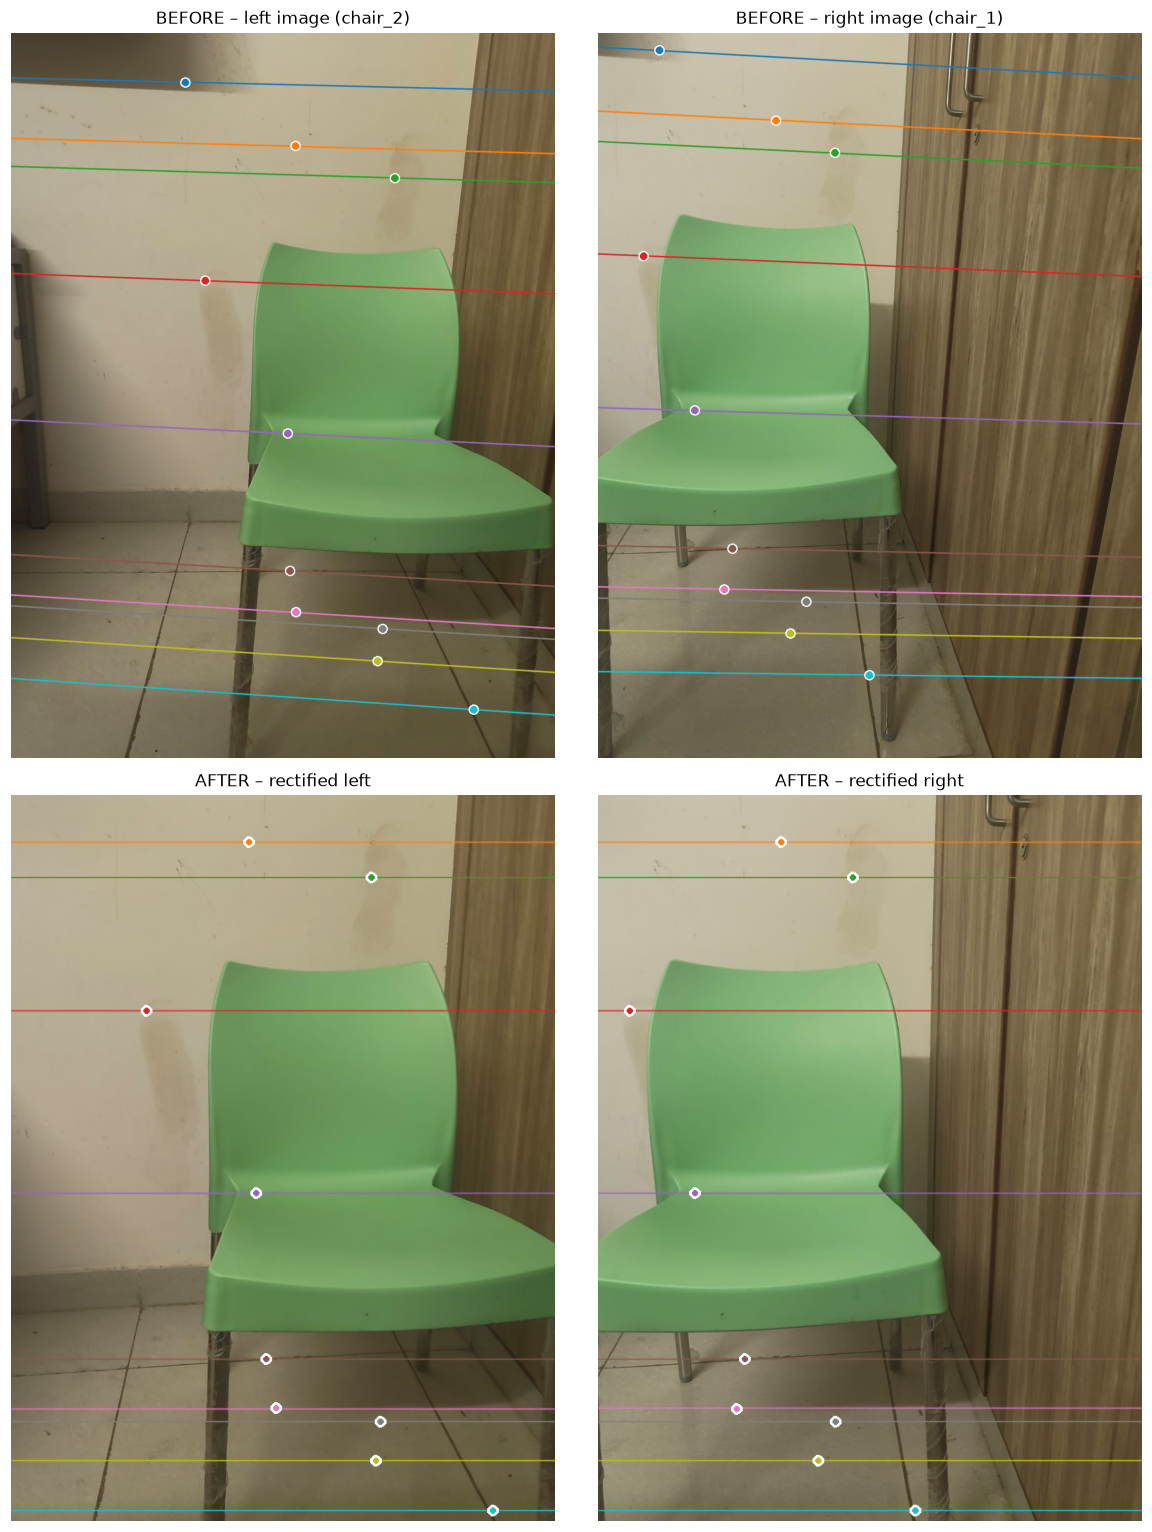

In [5]:
def skew(v):
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])


Ffin = np.linalg.inv(K).T @ skew(rc["t"].ravel()) @ rc["R"] @ np.linalg.inv(K)
pal = [tuple(int(255 * c) for c in plt.cm.tab10(i)[:3]) for i in range(10)]


def draw_epi(img_a, img_b, pa, pb, Fm=None, lw=2, rad=10):
    a_, b_ = img_a.copy(), img_b.copy()
    H_, W_ = a_.shape[:2]
    if Fm is not None:
        lb = cv2.computeCorrespondEpilines(pa.reshape(-1, 1, 2), 1, Fm).reshape(-1, 3)
        la = cv2.computeCorrespondEpilines(pb.reshape(-1, 1, 2), 2, Fm).reshape(-1, 3)
    else:
        lb = np.array([[0, 1, -p[1]] for p in pa])
        la = np.array([[0, 1, -p[1]] for p in pb])
    for img, ls in [(a_, la), (b_, lb)]:
        for (x, y, c_), col in zip(ls, pal):
            cv2.line(
                img,
                (0, int(-c_ / y)),
                (W_, int(-(c_ + x * W_) / y)),
                col,
                lw,
                cv2.LINE_AA,
            )
    for p, col in zip(pa, pal):
        cv2.circle(a_, tuple(np.int32(p)), rad, col, -1)
        cv2.circle(a_, tuple(np.int32(p)), rad, (255, 255, 255), 2)
    for p, col in zip(pb, pal):
        cv2.circle(b_, tuple(np.int32(p)), rad, col, -1)
        cv2.circle(b_, tuple(np.int32(p)), rad, (255, 255, 255), 2)
    return a_, b_


sel_idx = np.argsort(qL[:, 1])[
    np.linspace(0, len(qL) - 1, 10).astype(int)
]  # 10 matches spread over the image height
bL, bR = draw_epi(imL, imR, oL[sel_idx], oR[sel_idx], Ffin)
aL, aR = draw_epi(rL, rR, qL[sel_idx], qR[sel_idx], None, lw=1, rad=5)
xa, xb = np.c_[oL[sel_idx], np.ones(10)], np.c_[oR[sel_idx], np.ones(10)]
ln = xa @ Ffin.T
print(
    "mean point-to-epipolar-line distance of these 10 matches in the original images: %.2f px (full resolution)"
    % np.mean(np.abs(np.sum(xb * ln, axis=1)) / np.hypot(ln[:, 0], ln[:, 1]))
)
fig, axs = plt.subplots(2, 2, figsize=(11, 14))
for ax, im, t in zip(
    axs.ravel(),
    [bL, bR, aL, aR],
    [
        "BEFORE – left image (chair_2)",
        "BEFORE – right image (chair_1)",
        "AFTER – rectified left",
        "AFTER – rectified right",
    ],
):
    ax.imshow(im)
    ax.set_title(t)
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT / "q3_epipolar_before_after.png", dpi=120)
plt.show()


## 3. Disparity map (Task 2) — Semi-Global Block Matching
`cv2.StereoSGBM` (Hirschmuller) on the rectified pair: smoothness penalties P1, P2 on neighbouring disparity differences solve a 1-D dynamic programme from 8 directions. The disparity search range is set from the sparse feature disparities (± margin). The **right-view disparity** is computed too (needed for the left–right consistency check).

search range d in [28, 300) px
pixels with a disparity estimate: 55.2 % of the rectified overlap


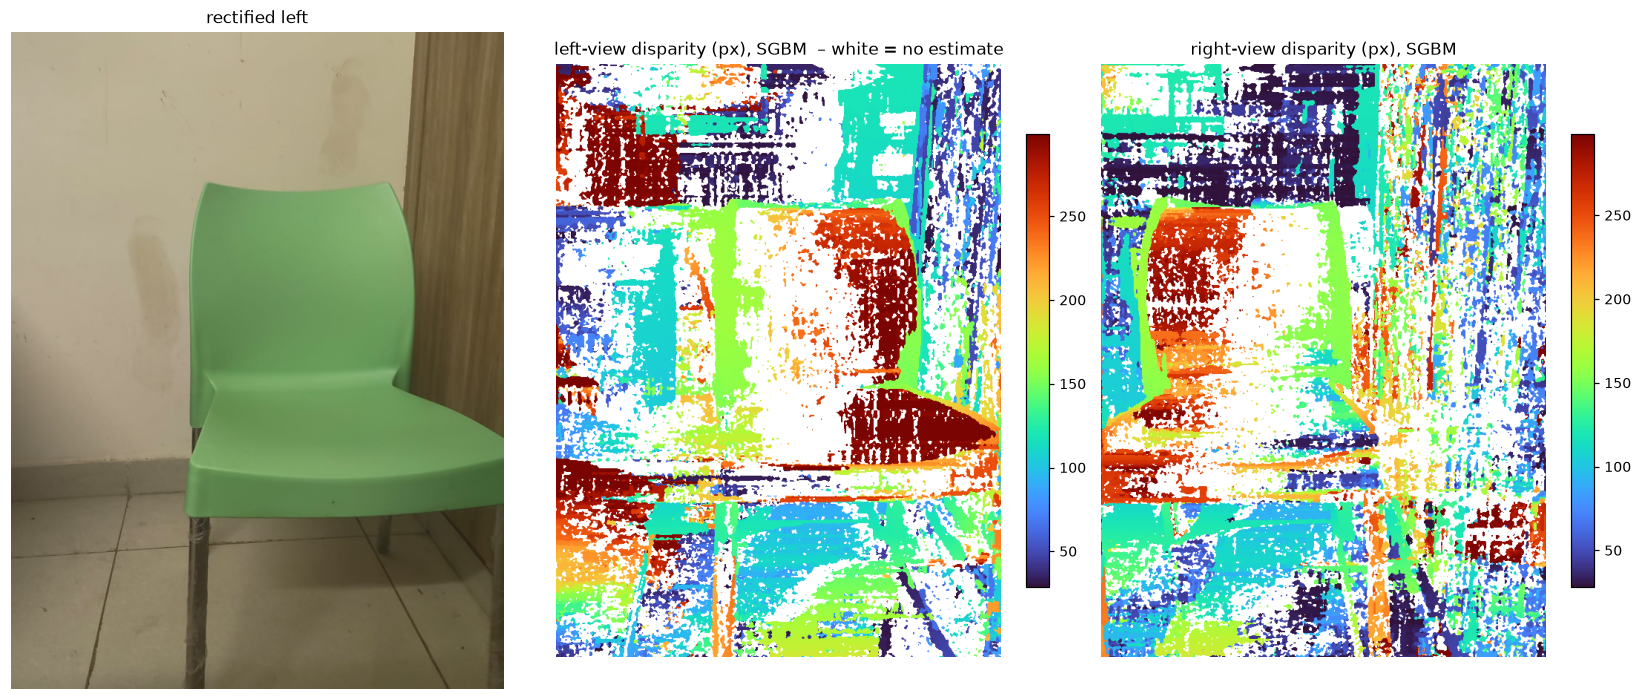

In [6]:
dmin = int(np.floor(np.percentile(d_feat, 1) - 30))
dmax = int(np.ceil(np.percentile(d_feat, 99) + 30))
nd = int(np.ceil((dmax - dmin) / 16) * 16)
print(f"search range d in [{dmin}, {dmin+nd}) px")


def make_sgbm(bs, mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY, uniq=0, lam=1.0):
    return cv2.StereoSGBM_create(
        minDisparity=dmin,
        numDisparities=nd,
        blockSize=bs,
        P1=int(8 * 3 * bs * bs * lam),
        P2=int(32 * 3 * bs * bs * lam),
        disp12MaxDiff=-1,
        uniquenessRatio=uniq,
        speckleWindowSize=0,
        speckleRange=2,
        preFilterCap=63,
        mode=mode,
    )


PAD = (
    dmin + nd
)  # SGBM cannot estimate the first (dmin+nd) columns of the left image (no matching pixels exist in the right image) -> pad with mirrored columns, crop afterwards


def padL(im):
    return cv2.copyMakeBorder(im, 0, 0, PAD, 0, cv2.BORDER_REFLECT_101)


def padR(im):
    return cv2.copyMakeBorder(im, 0, 0, 0, PAD, cv2.BORDER_REFLECT_101)


sg = make_sgbm(5)
dispL = (sg.compute(padL(rL), padL(rR)).astype(np.float32) / 16.0)[
    :, PAD:
]  # left-view disparity, invalid = dmin-1
# right-view disparity: flip images, swap roles, flip result, negate sign convention
sgR = cv2.StereoSGBM_create(
    minDisparity=-(dmin + nd - 1),
    numDisparities=nd,
    blockSize=5,
    P1=int(8 * 3 * 25),
    P2=int(32 * 3 * 25),
    disp12MaxDiff=-1,
    uniquenessRatio=0,
    speckleWindowSize=0,
    speckleRange=2,
    preFilterCap=63,
    mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY,
)
dispR_raw = (sgR.compute(padR(rR), padR(rL)).astype(np.float32) / 16.0)[
    :, :w
]  # matches right pixel x_R with left pixel x_R - dR  (dR in [-(dmax),..])
dispR = -dispR_raw  # positive disparity convention
invL = dispL <= dmin
invR = dispR_raw <= -(dmin + nd - 1)
dispL[invL] = np.nan
dispR[invR] = np.nan
# second, differently-configured matcher (bigger window, stronger smoothing) for a cross-check
disp2 = (make_sgbm(11, lam=2.0).compute(padL(rL), padL(rR)).astype(np.float32) / 16.0)[
    :, PAD:
]
disp2[disp2 <= dmin] = np.nan
# a left pixel x has a right counterpart x-d: restrict to where it is inside the right image
print(
    "pixels with a disparity estimate: %.1f %% of the rectified overlap"
    % (100 * np.mean(~np.isnan(dispL)[valid_area]))
)

fig, axs = plt.subplots(1, 3, figsize=(15, 7.2))
axs[0].imshow(rL)
axs[0].set_title("rectified left")
im0 = axs[1].imshow(dispL, cmap="turbo")
axs[1].set_title("left-view disparity (px), SGBM  – white = no estimate")
plt.colorbar(im0, ax=axs[1], fraction=0.046)
im1 = axs[2].imshow(dispR, cmap="turbo")
axs[2].set_title("right-view disparity (px), SGBM")
plt.colorbar(im1, ax=axs[2], fraction=0.046)
for a in axs:
    a.axis("off")
plt.tight_layout()
plt.savefig(OUT / "q3_disparity.png", dpi=130)
plt.show()


## 4. Disparity → depth (Task 3)
`Z = f·B / d` with the rectified focal length `f`. Handling of bad values:
* `d ≤ 0` (zero / negative → at or beyond infinity, physically impossible for a point in front of the cameras) → **invalid**, `Z = NaN`
* pixels where SGBM found no match (`d` below the search range) → **invalid**
* `d` smaller than `d_min_valid` (depth beyond a chosen range, here 6 m) → **invalid / out of range** – such a tiny disparity is of the order of the matching noise
* `Z` is also clipped to `[0.2 m, 6 m]` for display only.

                            pixels  percent
d<=0 (zero/negative)             0      0.0
no match found              215089     44.8
0<d<21.3 px (beyond 6.0 m)       0      0.0
valid depth                 264911     55.2


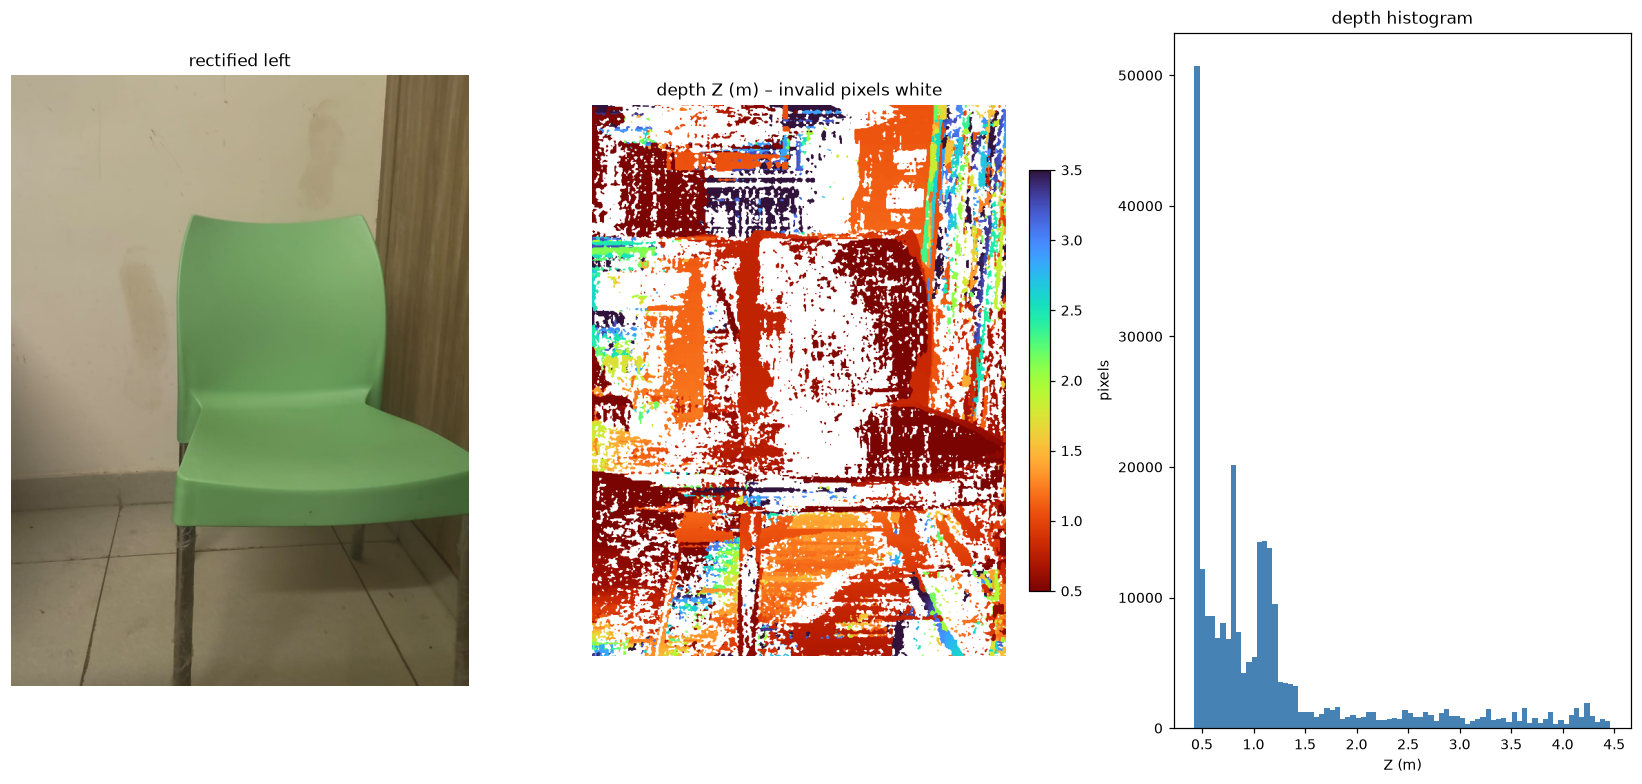

SGBM vs. SIFT-feature disparity at 140 keypoints: median |error| 0.61 px, 90th percentile 100.04 px


In [7]:
Z_MIN, Z_MAX = 0.2, 6.0
d_min_valid = fB / Z_MAX


def disp_to_depth(d, fB=fB):
    Z = np.full(d.shape, np.nan, np.float32)
    ok = np.isfinite(d) & (d >= d_min_valid)
    Z[ok] = fB / d[ok]
    Z[(Z < Z_MIN) | (Z > Z_MAX)] = np.nan
    return Z


Z = disp_to_depth(dispL)
cats = {
    "d<=0 (zero/negative)": np.nansum(dispL <= 0),
    "no match found": np.sum(invL & valid_area),
    f"0<d<{d_min_valid:.1f} px (beyond {Z_MAX} m)": np.nansum(
        (dispL > 0) & (dispL < d_min_valid)
    ),
    "valid depth": np.sum(np.isfinite(Z)),
}
print(
    pd.Series(cats, name="pixels")
    .to_frame()
    .assign(percent=lambda x: (100 * x["pixels"] / valid_area.sum()).round(1))
)
fig, axs = plt.subplots(1, 3, figsize=(15, 7.2))
axs[0].imshow(rL)
axs[0].set_title("rectified left")
im0 = axs[1].imshow(Z, cmap="turbo_r", vmin=Z_MIN + 0.3, vmax=3.5)
axs[1].set_title("depth Z (m) – invalid pixels white")
plt.colorbar(im0, ax=axs[1], fraction=0.046)
axs[2].hist(Z[np.isfinite(Z)], bins=80, color="steelblue")
axs[2].set_xlabel("Z (m)")
axs[2].set_ylabel("pixels")
axs[2].set_title("depth histogram")
for a in axs[:2]:
    a.axis("off")
plt.tight_layout()
plt.savefig(OUT / "q3_depth.png", dpi=130)
plt.show()
# sparse sanity check: SGBM disparity at the SIFT keypoints vs. the keypoint disparity itself
xs, ys = np.round(qL[:, 0]).astype(int), np.round(qL[:, 1]).astype(int)
inb = (xs >= 0) & (xs < w) & (ys >= 0) & (ys < h)
dd = dispL[ys[inb], xs[inb]] - d_feat[inb]
ok = np.isfinite(dd)
print(
    f"SGBM vs. SIFT-feature disparity at {ok.sum()} keypoints: median |error| {np.median(np.abs(dd[ok])):.2f} px, 90th percentile {np.percentile(np.abs(dd[ok]), 90):.2f} px"
)


## 5. Where is depth unreliable? (Task 4)
I define five failure masks automatically (so the percentages are measurable) and then quantify how *noisy* the disparity actually is inside each one.
* **Textureless** – local intensity standard deviation (9×9) below a threshold → almost no information for block matching (wall, chair body, floor tiles).
* **Occluded / mismatched** – left–right consistency fails: `|d_L(x) − d_R(x − d_L(x))| > 1 px` (a half-occluded pixel has no true counterpart).
* **Object boundaries / depth discontinuities** – the consistent disparities inside a 7×7 window span more than 8 px (the matching window straddles two depths → "fattening" and mixed-depth estimates).
* **Specular / reflective** – saturated bright highlights (automatic: V > 225, S < 70) plus the chrome chair legs (marked manually as two boxes): the appearance of a reflection changes between the two views because it moves with the viewpoint.
* **Far range** – small disparity, where depth error explodes (analysed in Section 6).

,share of image (%),LR-inconsistent (%),median local disparity noise (px),two-matcher disagreement >2px (%)
region,,,,
textureless,64.39,81.19,8.79,22.47
occluded / LR-inconsistent,40.76,100.00,12.08,23.57
object boundary,14.40,52.59,13.15,28.62
specular / reflective,3.27,63.39,7.89,19.80
clean (none of the above),4.51,0.00,0.32,14.61


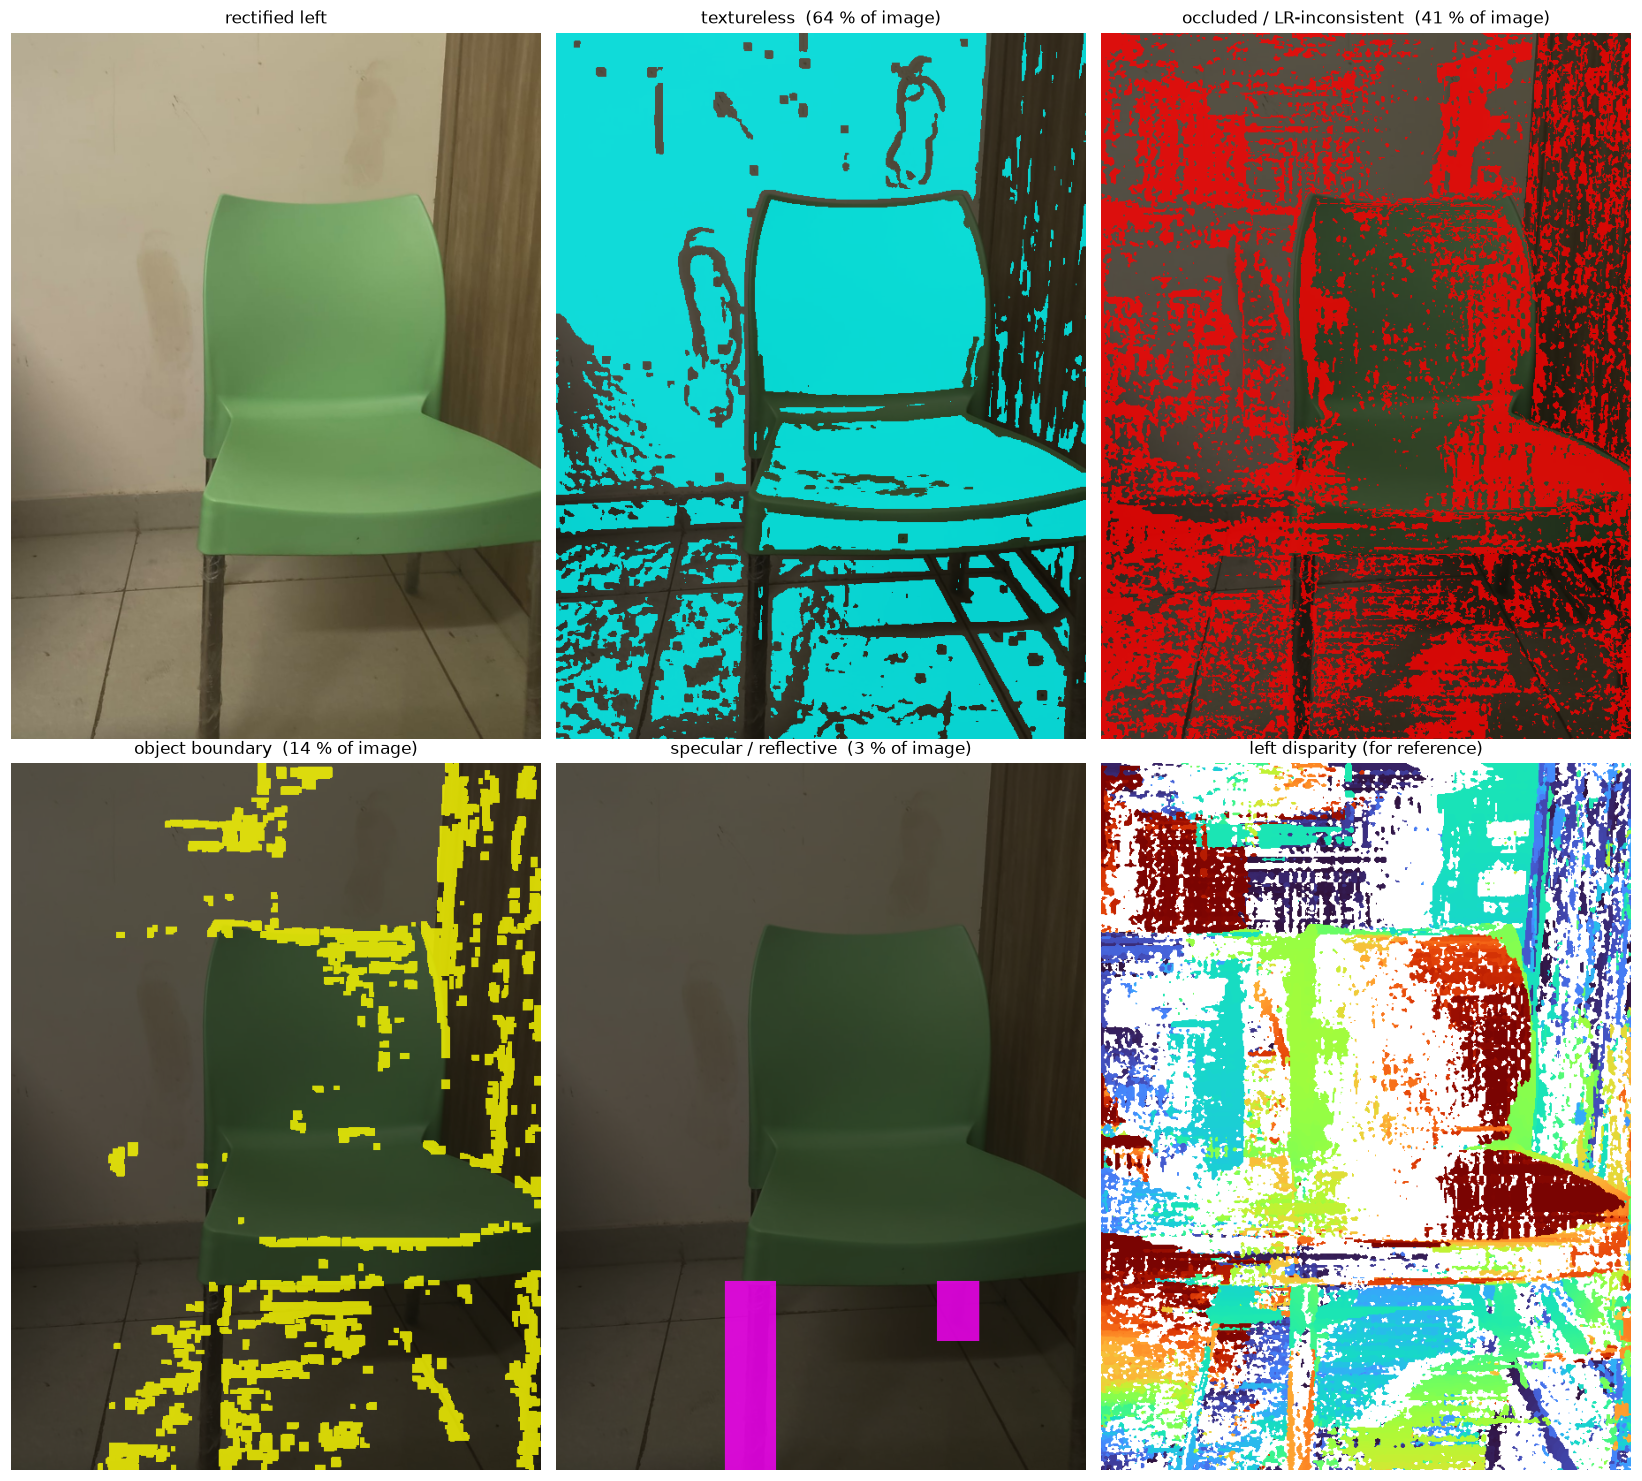

In [8]:
gf = rgL.astype(np.float32)
mu = cv2.blur(gf, (9, 9))
sd = np.sqrt(np.maximum(cv2.blur(gf * gf, (9, 9)) - mu * mu, 0))
textureless = (sd < 1.5) & valid_area
# left-right consistency
xx = np.arange(w)[None, :].repeat(h, 0).astype(np.float32)
yy = np.arange(h)[:, None].repeat(w, 1).astype(np.float32)
dR_at = cv2.remap(
    np.nan_to_num(dispR, nan=-9999),
    xx - np.nan_to_num(dispL, nan=0),
    yy,
    cv2.INTER_NEAREST,
    borderValue=-9999,
)
lr_err = np.abs(dispL - dR_at)
lr_err[dR_at < -9000] = np.inf
lr_err[~np.isfinite(dispL)] = np.nan
lrc_fail = (lr_err > 1.0) & valid_area
# boundaries
d_ok = np.where(
    np.isfinite(lr_err) & (lr_err <= 1.0), dispL, np.nan
)  # only left-right-consistent disparities
hi = np.where(np.isfinite(d_ok), d_ok, -1e4).astype(np.float32)
lo = np.where(np.isfinite(d_ok), d_ok, 1e4).astype(np.float32)
rng = cv2.dilate(hi, np.ones((7, 7), np.uint8)) - cv2.erode(
    lo, np.ones((7, 7), np.uint8)
)  # disparity range inside every 7x7 window
boundary = (
    cv2.dilate(
        ((rng > 8) & (rng < 1e3)).astype(np.uint8), np.ones((5, 5), np.uint8)
    ).astype(bool)
    & valid_area
)
# specular
hsv = cv2.cvtColor(rL, cv2.COLOR_RGB2HSV)
bright = (hsv[..., 2] > 225) & (hsv[..., 1] < 70)
legs = np.zeros(
    (h, w), bool
)  # chrome chair legs: marked manually as boxes in the rectified left image (half-res px): front-left leg and rear-left leg
for x0, x1, y0, y1 in [(195, 245, 590, h), (435, 475, 590, 650)]:
    legs[y0:y1, x0:x1] = True
specular = (
    cv2.dilate((bright | legs).astype(np.uint8), np.ones((9, 9), np.uint8)).astype(bool)
    & valid_area
)
masks = {
    "textureless": textureless,
    "occluded / LR-inconsistent": lrc_fail,
    "object boundary": boundary,
    "specular / reflective": specular,
}

# local disparity noise = std of disparity in 7x7 neighbourhood after removing a planar trend (use Laplacian-type residual)
dn = np.nan_to_num(dispL, nan=np.nanmedian(dispL))
loc = np.abs(dn - cv2.blur(dn, (7, 7)))
clean = (
    valid_area & ~textureless & ~lrc_fail & ~boundary & ~specular & np.isfinite(dispL)
)
rows = []
for nm, M in list(masks.items()) + [("clean (none of the above)", clean)]:
    sel = M & np.isfinite(dispL)
    rows.append(
        {
            "region": nm,
            "share of image (%)": 100 * M.sum() / valid_area.sum(),
            "LR-inconsistent (%)": (
                100 * np.mean(lr_err[sel] > 1) if sel.sum() else np.nan
            ),
            "median local disparity noise (px)": np.median(loc[sel]),
            "two-matcher disagreement >2px (%)": 100
            * np.mean(np.abs(dispL - disp2)[sel] > 2),
        }
    )
tab = pd.DataFrame(rows).set_index("region")
display(tab.round(2))
tab.round(3).to_csv(OUT / "q3_failure_regions.csv")

fig, axs = plt.subplots(2, 3, figsize=(15, 13.5))
axs[0, 0].imshow(rL)
axs[0, 0].set_title("rectified left")
for ax, (nm, M), col in zip(
    axs.ravel()[1:5], masks.items(), [(0, 1, 1), (1, 0, 0), (1, 1, 0), (1, 0, 1)]
):
    ov = rL.astype(np.float32) / 255 * 0.45
    ov[M] = ov[M] * 0.2 + np.array(col) * 0.8
    ax.imshow(np.clip(ov, 0, 1))
    ax.set_title(f"{nm}  ({100*M.sum()/valid_area.sum():.0f} % of image)")
axs[1, 2].imshow(dispL, cmap="turbo")
axs[1, 2].set_title("left disparity (for reference)")
for a in axs.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig(OUT / "q3_failure_regions.png", dpi=120)
plt.show()


## 6. Relationship between disparity and depth, and error propagation (Task 5)
Depth is a **hyperbolic** function of disparity, `Z = fB/d`. Differentiating, `|dZ/dd| = fB/d² = Z²/(fB)`, so a fixed disparity error `δd` gives a depth error

$$\delta Z \;\approx\; \frac{Z^{2}}{f B}\,\delta d, \qquad \frac{\delta Z}{Z} \;\approx\; \frac{Z}{fB}\,\delta d = \frac{\delta d}{d}.$$

The depth error grows with the **square** of the distance; the *relative* error equals `δd/d`, which is large when `d` is small, i.e. far away.

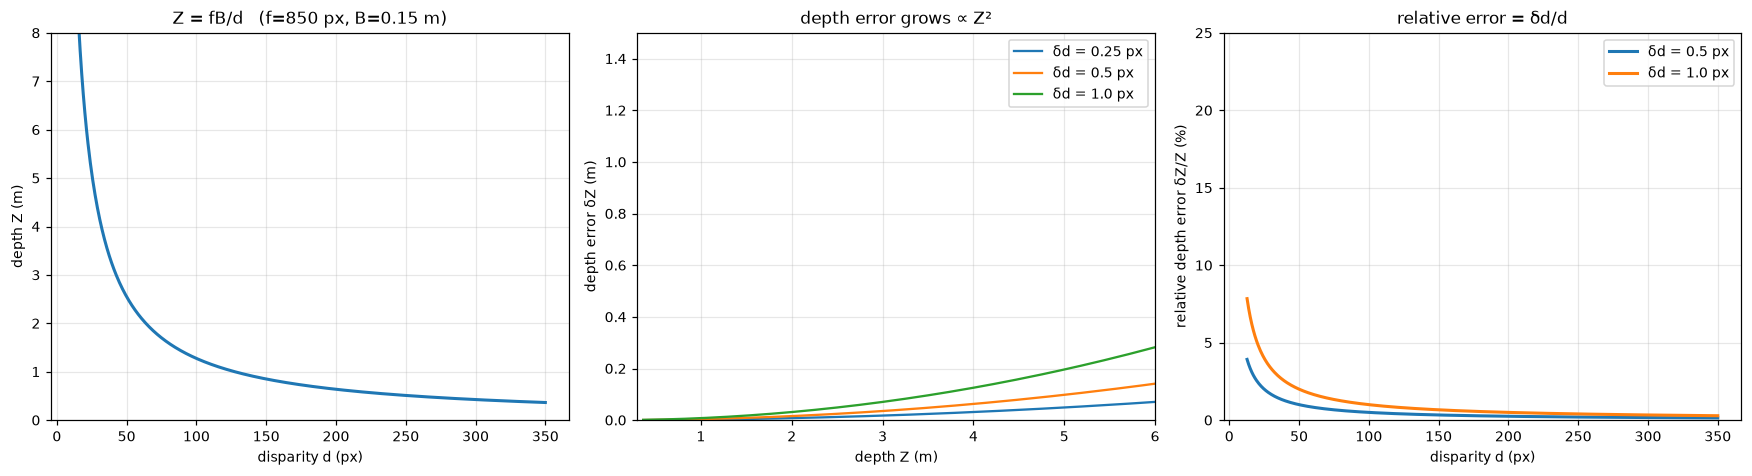

Examples (δd = 0.5 px):
  Z = 0.8 m → d =  159.4 px,  δZ =   0.3 cm  (0.3 %)
  Z = 1.0 m → d =  127.5 px,  δZ =   0.4 cm  (0.4 %)
  Z = 1.5 m → d =   85.0 px,  δZ =   0.9 cm  (0.6 %)
  Z = 2.0 m → d =   63.8 px,  δZ =   1.6 cm  (0.8 %)
  Z = 3.0 m → d =   42.5 px,  δZ =   3.5 cm  (1.2 %)
  Z = 5.0 m → d =   25.5 px,  δZ =   9.8 cm  (2.0 %)


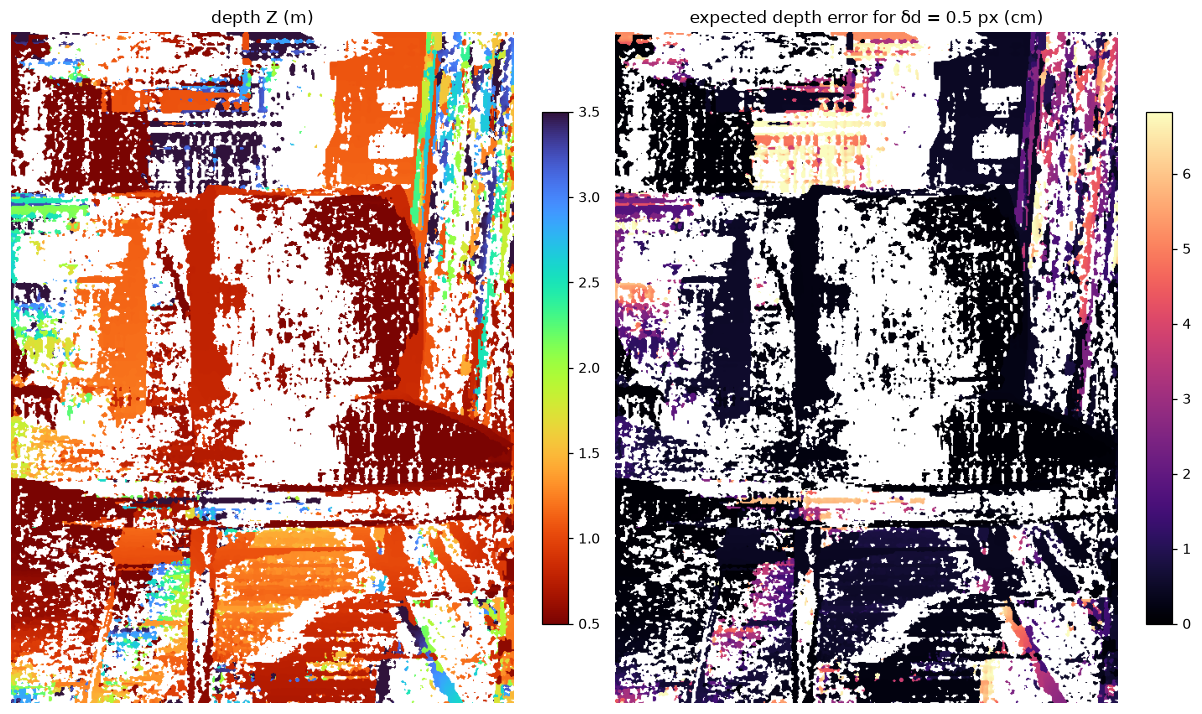

Z range at the matched keypoints: 0.49 – 3.53 m


In [9]:
dgrid = np.linspace(d_min_valid * 0.6, 350, 600)
Zg = fB / dgrid
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
axs[0].plot(dgrid, Zg, lw=2)
axs[0].set_ylim(0, 8)
axs[0].set_xlabel("disparity d (px)")
axs[0].set_ylabel("depth Z (m)")
axs[0].set_title(f"Z = fB/d   (f={f_rect:.0f} px, B={B_M} m)")
axs[0].grid(alpha=0.3)
for e_ in [0.25, 0.5, 1.0]:
    axs[1].plot(Zg, Zg**2 / fB * e_, label=f"δd = {e_} px")
axs[1].set_xlim(0.3, 6)
axs[1].set_ylim(0, 1.5)
axs[1].set_xlabel("depth Z (m)")
axs[1].set_ylabel("depth error δZ (m)")
axs[1].set_title("depth error grows ∝ Z²")
axs[1].legend()
axs[1].grid(alpha=0.3)
axs[2].plot(dgrid, 100 * 0.5 / dgrid, lw=2, label="δd = 0.5 px")
axs[2].plot(dgrid, 100 * 1.0 / dgrid, lw=2, label="δd = 1.0 px")
axs[2].set_ylim(0, 25)
axs[2].set_xlabel("disparity d (px)")
axs[2].set_ylabel("relative depth error δZ/Z (%)")
axs[2].set_title("relative error = δd/d")
axs[2].legend()
axs[2].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "q3_disparity_depth_error.png", dpi=130)
plt.show()
print("Examples (δd = 0.5 px):")
for Zq in [0.8, 1.0, 1.5, 2.0, 3.0, 5.0]:
    print(
        f"  Z = {Zq:3.1f} m → d = {fB/Zq:6.1f} px,  δZ = {Zq**2/fB*0.5*100:5.1f} cm  ({100*0.5/(fB/Zq):.1f} %)"
    )

# measured: depth uncertainty map for σ_d = 0.5 px
dZ_map = Z**2 / fB * 0.5
fig, axs = plt.subplots(1, 2, figsize=(11, 7))
im = axs[0].imshow(Z, cmap="turbo_r", vmin=0.5, vmax=3.5)
axs[0].set_title("depth Z (m)")
plt.colorbar(im, ax=axs[0], fraction=0.046)
im = axs[1].imshow(
    100 * dZ_map, cmap="magma", vmin=0, vmax=np.nanpercentile(100 * dZ_map, 98)
)
axs[1].set_title("expected depth error for δd = 0.5 px (cm)")
plt.colorbar(im, ax=axs[1], fraction=0.046)
for a in axs:
    a.axis("off")
plt.tight_layout()
plt.savefig(OUT / "q3_depth_uncertainty.png", dpi=130)
plt.show()
dsel = dispL[ys[inb], xs[inb]]
print(
    f"Z range at the matched keypoints: {fB/np.nanmax(d_feat):.2f} – {fB/np.nanmin(d_feat):.2f} m"
)


## 7. Consistency check and reliability map (Task 6)
**Rule-based classifier** for every pixel of the left disparity map:

| class | colour | criterion |
|---|---|---|
| **Invalid** | red | no SGBM estimate, `d ≤ d_min_valid`, **or** left–right error > 2 px (occluded / mismatched) |
| **Uncertain** | yellow | LR error in (1, 2] px, **or** two independent matchers (5×5 vs 11×11 window, different smoothness) disagree by > 2 px, **or** textureless, **or** near a depth discontinuity, **or** specular, **or** expected depth error δZ/Z > 10 % for δd = 0.5 px |
| **Reliable** | green | passes all of the above |

*The left–right check is the core test:* for a correct match, looking back from the right image must return to the same left pixel; for occlusions and mismatches it does not.

{'reliable': np.float64(2.0), 'uncertain': np.float64(13.2), 'invalid': np.float64(84.9)} (% of rectified overlap)


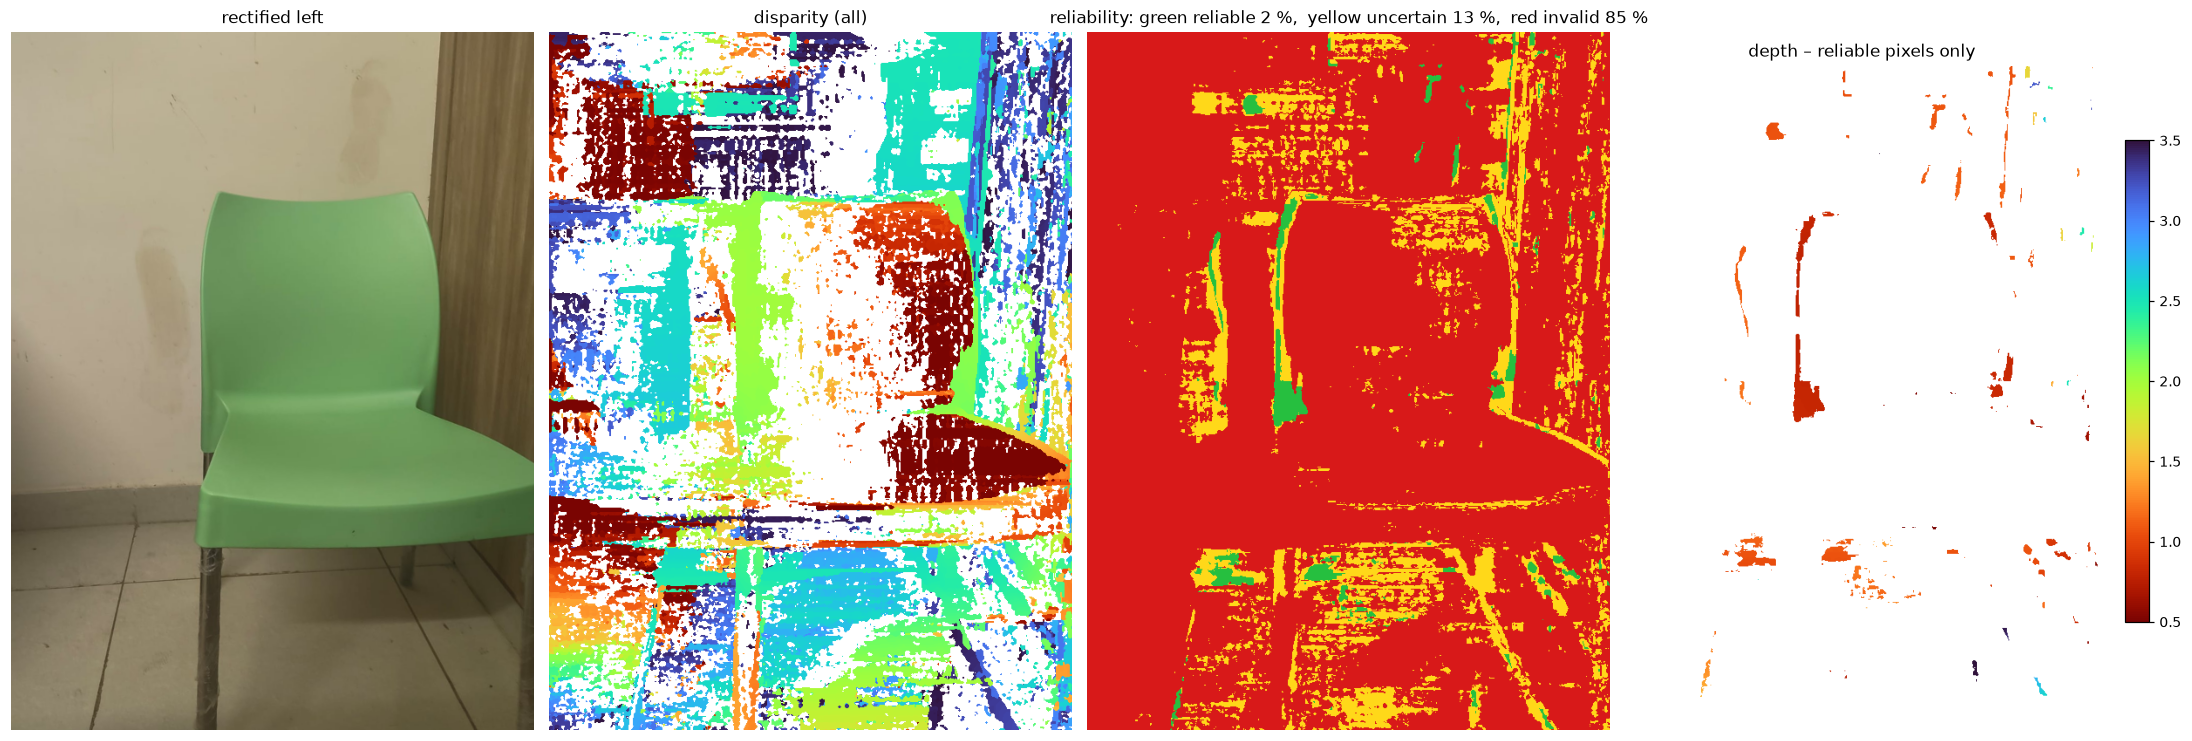

In [10]:
lr = lr_err.copy()
inv_final = ~np.isfinite(dispL) | (dispL < d_min_valid) | (lr > 2.0) | ~valid_area
matcher_dis = np.abs(dispL - disp2) > 2.0
matcher_dis |= np.isnan(disp2)
rel_err_far = (0.5 / np.where(np.isfinite(dispL), dispL, 1e-3)) > 0.10
unc = (
    (lr > 1.0) | matcher_dis | textureless | boundary | specular | rel_err_far
) & ~inv_final
rel = ~inv_final & ~unc
cmap_rgb = np.zeros((h, w, 3), np.float32)
cmap_rgb[rel] = [0.15, 0.75, 0.25]
cmap_rgb[unc] = [1.0, 0.85, 0.1]
cmap_rgb[inv_final] = [0.85, 0.1, 0.1]
cmap_rgb[~valid_area] = 0.15
frac = {
    k: 100 * v[valid_area].sum() / valid_area.sum()
    for k, v in [("reliable", rel), ("uncertain", unc), ("invalid", inv_final)]
}
print({k: round(v, 1) for k, v in frac.items()}, "(% of rectified overlap)")

Zrel = Z.copy()
Zrel[~rel] = np.nan
fig, axs = plt.subplots(1, 4, figsize=(20, 8))
axs[0].imshow(rL)
axs[0].set_title("rectified left")
im = axs[1].imshow(dispL, cmap="turbo")
axs[1].set_title("disparity (all)")
axs[2].imshow(cmap_rgb)
axs[2].set_title(
    f'reliability: green reliable {frac["reliable"]:.0f} %,  yellow uncertain {frac["uncertain"]:.0f} %,  red invalid {frac["invalid"]:.0f} %'
)
im = axs[3].imshow(Zrel, cmap="turbo_r", vmin=0.5, vmax=3.5)
axs[3].set_title("depth – reliable pixels only")
plt.colorbar(im, ax=axs[3], fraction=0.046)
for a in axs:
    a.axis("off")
plt.tight_layout()
plt.savefig(OUT / "q3_reliability_map.png", dpi=130)
plt.show()


### Does the consistency check actually identify wrong disparities? (independent validation)
There is no ground-truth depth, but the SIFT matches (used *only* to build the rectification, never as input to SGBM) give a sparse **independent reference**: disparity of a keypoint = `x_L − x_R` in the rectified frames. I compare SGBM's disparity at those keypoints for each reliability class.

In [11]:
cls = np.where(rel, 0, np.where(unc, 1, 2))[ys[inb], xs[inb]]
dd_all = dispL[ys[inb], xs[inb]] - d_feat[inb]
# also use a 3x3 neighbourhood median to be robust to sub-pixel keypoint location
rows = []
for c, nm in enumerate(["reliable", "uncertain", "invalid"]):
    s_ = cls == c
    e_ = np.abs(dd_all[s_])
    e_ = e_[np.isfinite(e_)]
    rows.append(
        {
            "class": nm,
            "keypoints": int(s_.sum()),
            "with SGBM estimate": len(e_),
            "median |error| (px)": np.median(e_) if len(e_) else np.nan,
            "% with |error| > 2 px": 100 * np.mean(e_ > 2) if len(e_) else np.nan,
        }
    )
vt = pd.DataFrame(rows).set_index("class")
display(vt.round(2))
vt.round(3).to_csv(OUT / "q3_validation.csv")
e_all = np.abs(dd_all[np.isfinite(dd_all)])
print(
    f"all keypoints with an estimate: median |error| {np.median(e_all):.2f} px, {100*np.mean(e_all > 2):.0f} % wrong by > 2 px"
)


,keypoints,with SGBM estimate,median |error| (px),% with |error| > 2 px
class,,,,
reliable,21,21,0.23,0.00
uncertain,35,35,0.88,37.14
invalid,125,84,0.87,40.48


all keypoints with an estimate: median |error| 0.61 px, 34 % wrong by > 2 px


## 8. Discussion
### Summary of results (numbers from the run above, all at half-resolution unless noted)
* **Rectification (Task 1).** Median vertical misalignment of the verified matches fell from **28.0 px** (95th percentile 35.5 px) to **0.23 px** (95th 0.55 px); the final relative pose is a small yaw (≈ −5°) plus a mainly horizontal translation (direction [−0.998, −0.032, −0.045]). The first rectification from the wall/floor-only matches left a ≈ 20 px row error on the chair; after the iterative refinement the median `|Δy|` of independently verified matches is ≈ 0.5 px (table above).
* **Disparity / depth (Tasks 2–3).** SGBM returns a disparity for 55 % of the pixels. The valid pixels have disparities of ≈ 28–300 px, i.e. depths of ≈ 0.4–3.5 m with the *assumed* `f = 700 px (full res), B = 0.15 m` (chair ≈ 0.5–0.6 m, wall ≈ 1 m, floor/cabinet edge up to ≈ 3 m). No pixel had `d ≤ 0`; the invalid ones (45 %) are the pixels for which SGBM found no match; no disparity was below the 6 m range limit. At 140 SIFT keypoints SGBM's disparity differs from the keypoint's own disparity by a median of **0.61 px**. (The 90th percentile is ≈ 100 px: a number of the SIFT references – and some SGBM values – are themselves wrong, see below.)
* **Reliability (Task 6).** Of the rectified overlap, **2 %** is classed *reliable*, **13 %** *uncertain* and **85 %** *invalid* (45 % no estimate + 40 % failing the left–right check). Against the independent keypoint reference the classes behave as intended: *reliable* keypoints (21) have a median error of 0.23 px and **0 %** are wrong by more than 2 px; the *uncertain* and *invalid* classes have median errors of 0.88 / 0.87 px and **37 % / 40 %** gross errors (> 2 px).

### Task 4 – at least three regions where depth is unreliable
| Region | Share of image | Evidence |
|---|---|---|
| **Textureless surfaces** (plain wall, green chair body, floor tiles) | 64 % | 81 % of these pixels fail the left–right check; median local disparity noise **8.8 px** versus **0.3 px** in clean regions. Block matching has no information – the cost curve is flat, so noise or the smoothness prior decides the disparity (visible as streaks in the disparity map). |
| **Occluded / mismatched pixels** (to the left of the chair/cabinet, background revealed in one view only; image borders) | 41 % fail the L–R check | A half-occluded pixel has no true counterpart, so SGBM returns the best *wrong* match; the right-to-left lookup does not return to the same pixel. The chair is ≈ 0.5 m from the camera with ≈ 200 px disparity, so a very large strip of wall is hidden behind it in one of the views. |
| **Object boundaries / depth discontinuities** (chair outline, chair/cabinet edge, floor–wall edge) | 14 % | Within 7×7 windows the consistent disparities span > 8 px; local disparity noise 13 px and 29 % disagreement between two independent matchers (vs 15 % in clean areas): matching windows straddle foreground and background ("fattening", mixed estimates). |
| **Reflective / specular** (chrome legs, bright highlights on the glossy tiles) | 3 % | 63 % of the pixels fail the L–R check; the reflection moves with the viewpoint so the two views disagree. |
| **Far range** | – | In this scene depths stay below ≈ 3.5 m so δZ/Z for δd = 0.5 px is ≤ 1.4 %; for a distant scene this would dominate (Section 6). |

### Task 5 – disparity vs depth, and why a small disparity error hurts far objects
`Z = fB/d` is a hyperbola: depth is **inversely** proportional to disparity. Differentiating, `δZ = (Z² / fB)·δd` – the same disparity error produces a depth error that grows with the **square** of the distance, and the *relative* error `δZ/Z = δd/d` is large when `d` is small. Numerically (δd = 0.5 px at working resolution, `fB = 127.5 px·m`): at 1 m δZ ≈ 0.4 cm (0.4 %), at 3 m ≈ 3.5 cm (1.2 %), at 5 m ≈ 9.8 cm (2.0 %); between d = 40 px and d = 41 px the depth changes by 8 cm, but between d = 4 px and d = 5 px (≈ 25 m → 32 m) it changes by metres. The far wall and floor – where disparity is small – therefore have the poorest depth precision, even when matching is "correct"; sub-pixel interpolation, a larger baseline or a longer focal length are the only ways to improve far-range precision. Note also that the one-pixel quantisation of the disparity makes distant depth come out in coarse "steps".

### Task 6 – consistency check
The rule-based classifier above combines (i) **left–right consistency** (`|d_L(x) − d_R(x − d_L(x))|` ≤ 1 px = consistent, > 2 px = invalid), (ii) agreement of **two independent SGBM runs** (5×5 window vs 11×11 window with 2× stronger smoothing, tolerance 2 px), (iii) texture, boundary and specular masks, and (iv) the **propagated depth error** δZ/Z (> 10 % = uncertain). The result (green = reliable, yellow = uncertain, red = invalid) is shown in the four-panel reliability figure. Validation against the sparse SIFT disparities (table above) shows 0 % gross errors in the *reliable* class against 37–40 % in the others.

### Limitations
* **No real calibration.** `f = 1400 px` (full resolution) and `B = 0.15 m` are assumptions, and lens distortion is ignored. Metric depth scales with `f·B` – the *shape* of the depth map, the rectification quality, and the reliability analysis are unaffected, but the numbers in metres are only approximate. The rotation/translation direction comes from the essential matrix of ≈ 180 verified matches; its scale (the baseline) cannot be recovered from images alone.
* **Very hard test pair.** The photographs are hand-held, with ≈ 400 px of chair disparity, a −5° yaw between them and mostly plain surfaces, so SGBM leaves 45 % of the pixels without estimate and the reliable class is small (2 %). A real stereo rig (fixed baseline, synchronised, parallel axes) with a textured scene would give far denser reliable depth.
* **Reference data is imperfect.** The sparse SIFT disparities used for validation include some mismatches (the 90th percentile of the error is ≈ 100 px), so the absolute "wrong by > 2 px" rates are approximate; the *relative* difference between the classes is the meaningful result. The specular mask uses two hand-marked boxes for the chrome legs.
* Parameters of the classifier (thresholds 1 / 2 px, texture σ < 1.5, 8-px boundary range, 10 % depth error) were chosen by hand; they trade off the sizes of the three classes and were not optimised against ground truth. Disparity is computed at half resolution (and refined sub-pixel), so a 0.5 px working-resolution error equals 1 px at full size.
* The mirrored-border padding used to let SGBM estimate the leftmost columns can create spurious matches near the left/right image borders; these are mostly caught by the left–right check.